# 01 — PTB-XL Data Exploration

Look at what we're actually working with before training anything:
site/domain distribution, class balance, and a first look at raw
waveforms — all in plain language, matching Section 6.1 of the proposal.

Assumes `00_colab_setup.ipynb` has already been run in this runtime.

In [8]:
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive/MyDrive -maxdepth 3 -iname "*ptbxl*"

Mounted at /content/drive
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar


In [9]:
import os
REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"

if not os.path.exists("/content/mm-dg-healthcare"):
    !git clone {REPO_URL} /content/mm-dg-healthcare
%cd /content/mm-dg-healthcare
!pip install -q wfdb transformers pytest PyYAML tqdm scikit-learn pandas matplotlib

Cloning into '/content/mm-dg-healthcare'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (49/49), done.
remote: Total 53 (delta 3), reused 47 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 63.92 KiB | 1.78 MiB/s, done.
Resolving deltas: 100% (3/3), done.
/content/mm-dg-healthcare
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 1.4 MB/s eta 0:00:00


In [10]:
!mkdir -p data/raw
!tar xf /content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar -C data/raw
!ls data/raw/ptbxl | head

ptbxl_database.csv
records100
robots.txt
scp_statements.csv


In [11]:
!ls data/raw/ptbxl

ptbxl_database.csv  records100	robots.txt  scp_statements.csv


In [12]:
%cd /content/mm-dg-healthcare
import pandas as pd
import matplotlib.pyplot as plt
from src.data.ptbxl_dataset import load_ptbxl_metadata, DIAGNOSTIC_SUPERCLASSES

metadata = load_ptbxl_metadata("data/raw/ptbxl")
metadata.head()

/content/mm-dg-healthcare


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr,superclass
0,1,15709.0,56.0,1,NaN,63.0,2.0,0,CS-12 E,1984-11-09 09:17:34,...,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr,NORM
1,2,13243.0,19.0,0,NaN,70.0,2.0,0,CS-12 E,1984-11-14 12:55:37,...,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr,NORM
2,3,20372.0,37.0,1,NaN,69.0,2.0,0,CS-12 E,1984-11-15 12:49:10,...,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr,NORM
3,4,17014.0,24.0,0,NaN,82.0,2.0,0,CS-12 E,1984-11-15 13:44:57,...,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr,NORM
4,5,17448.0,19.0,1,NaN,70.0,2.0,0,CS-12 E,1984-11-17 10:43:15,...,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr,NORM


## Domain-shift axis: recording site

This is the column we'll split on to simulate "train at one hospital,
test at another," the same idea as the reference paper's Center A /
Center B experiments.

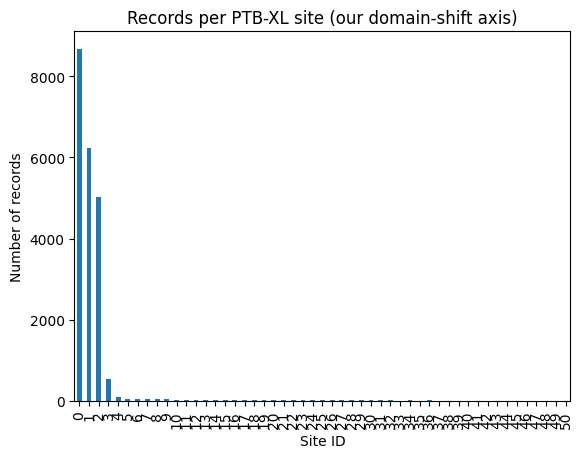

site
0     8671
1     6242
2     5019
3      550
4      100
5       57
6       46
7       43
8       43
9       38
10      36
11      32
12      25
13      24
14      25
15      25
16      22
17      20
18      17
19      15
20      18
21      18
22      15
23      13
24      14
25      13
26      15
27      15
28      15
29      15
30      12
31      13
32      13
33      10
34      12
35      11
36      12
37      10
38      10
39       8
40       9
41       9
42       6
43       6
44       7
45       6
46       4
47       4
48       4
49       3
50       2
Name: count, dtype: int64


In [13]:
site_counts = metadata["site"].value_counts().sort_index()
site_counts.plot(kind="bar", title="Records per PTB-XL site (our domain-shift axis)")
plt.xlabel("Site ID")
plt.ylabel("Number of records")
plt.show()

print(site_counts)

## Class balance per site

Worth checking whether the class balance itself shifts across sites —
if one site has almost no examples of a class, that's a harder
domain-shift pair to learn from and a natural first "hard" experiment.

In [14]:
pd.crosstab(metadata["site"], metadata["superclass"])

superclass,CD,HYP,MI,NORM,STTC
site,,,,,
0,1192,519,1956,3916,1088
1,1028,431,823,2775,1185
2,967,239,984,2014,815
3,95,59,137,147,112
4,16,11,21,35,17
5,11,4,9,20,13
6,6,3,3,22,12
7,9,2,6,22,4
8,9,3,6,19,6


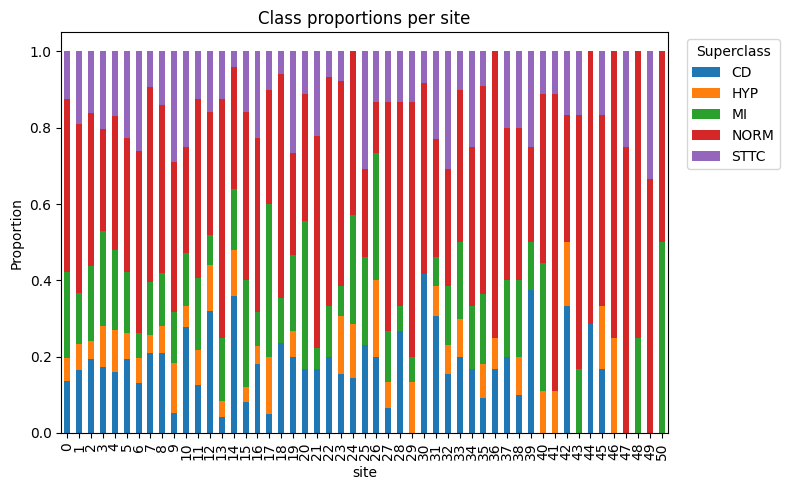

In [15]:
ct = pd.crosstab(metadata["site"], metadata["superclass"], normalize="index")
ct.plot(kind="bar", stacked=True, figsize=(8, 5), title="Class proportions per site")
plt.ylabel("Proportion")
plt.legend(title="Superclass", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## A first look at a raw waveform

Sanity-check that a record actually loads and looks like an ECG before
we trust anything downstream.

Record: ecg_id=1, superclass=NORM, site=0
Signal shape: (1000, 12) (samples, leads)
Lead names: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


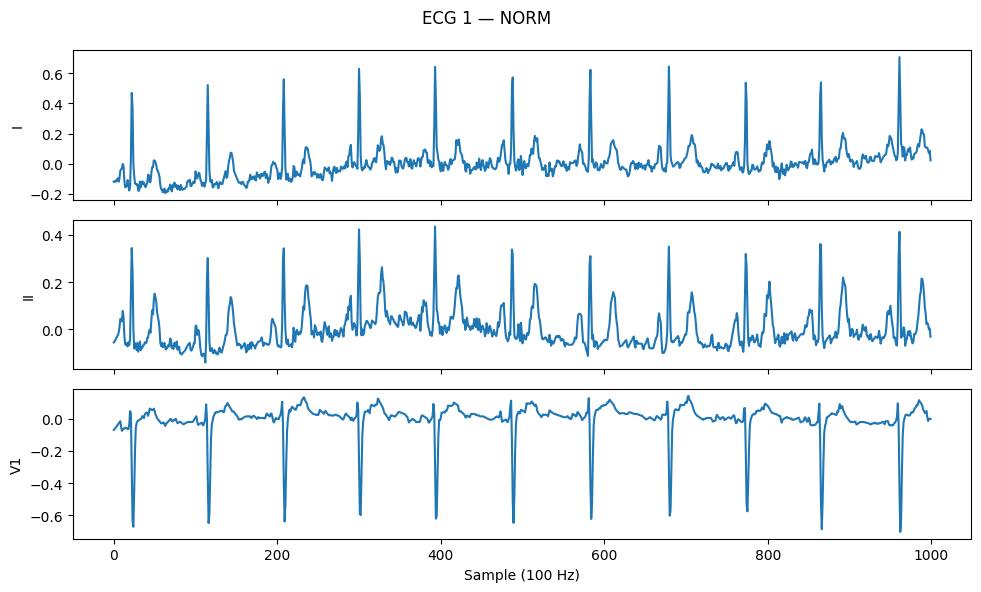

In [16]:
import wfdb
import numpy as np

row = metadata.iloc[0]
record_path = f"data/raw/ptbxl/{row['filename_lr']}"
signal, meta = wfdb.rdsamp(record_path)
print(f"Record: ecg_id={row['ecg_id']}, superclass={row['superclass']}, site={row['site']}")
print(f"Signal shape: {signal.shape} (samples, leads)")
print(f"Lead names: {meta['sig_name']}")

fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for ax, lead_idx, lead_name in zip(axes, [0, 1, 6], [meta['sig_name'][0], meta['sig_name'][1], meta['sig_name'][6]]):
    ax.plot(signal[:, lead_idx])
    ax.set_ylabel(lead_name)
axes[-1].set_xlabel("Sample (100 Hz)")
fig.suptitle(f"ECG {row['ecg_id']} — {row['superclass']}")
plt.tight_layout()
plt.show()

## Independent text modality preview (Phase 3 groundwork)

Even though fusion isn't built yet, we can already look at the
independent text each record maps to — this is the "second modality"
Phase 3 will use, and it's worth eyeballing now to judge how informative
(or how repetitive) it looks before investing in a text encoder.

In [18]:
from src.data.ptbxl_text import PTBXLTextLookup

text_lookup = PTBXLTextLookup("data/raw/ptbxl")
for _, row in metadata.sample(5, random_state=42).iterrows():
    text = text_lookup.get_text(row["scp_codes"])
    print(f"[{row['superclass']}] {text}")

[NORM] normal ECG; incomplete right bundle branch block; sinus bradycardia
[NORM] normal ECG; voltage criteria (QRS) for left ventricular hypertrophy; sinus bradycardia
[NORM] normal ECG; sinus rhythm
[NORM] normal ECG; sinus rhythm
[NORM] normal ECG; voltage criteria (QRS) for left ventricular hypertrophy; sinus rhythm


Continue to `02_baseline_signal_only.ipynb` to train the Phase 1 baseline.